<a href="https://colab.research.google.com/github/Ibru3636/EDA23bds0073project/blob/main/County_Murders_EDA_Modules_2_to_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BCSE331L – Exploratory Data Analysis Course Project (Modules 2–7)
## County Murders Dataset: Statistical Analysis, Clustering, PCA and Classification

**Student:** Mohammad ibrahim ahmad  
**Registration Number:** 23BDS0073

This notebook uses the dataset supplied at:
`https://raw.githubusercontent.com/salemprakash/EDA/main/Data/countymurders.csv`

The county-murders data is a county-year panel dataset. The published dataset description reports 37,349 observations and 20 variables, covering US counties over 1980–1996. Variables include murder counts and rates, arrests, population, population density, demographic percentages, income measures, unemployment-insurance payments, executions, and county/state identifiers.

**Project workflow:** load and inspect → clean and transform → univariate/bivariate/multivariate EDA → one- and two-dimensional statistical analysis → K-Means and hierarchical clustering → PCA → classification.

**Important modelling note:** the original data does not provide a ready-made categorical class label. For Module 7, this notebook creates an analytical binary target, `high_murdrate`, marking county-year observations whose murder rate is above the dataset median. This is a derived label for a classroom classification exercise, not an official crime category or a causal claim. Variables that directly encode the outcome (murder counts/rates and arrest counts/rates) are excluded from model predictors to avoid target leakage.

## 1. Import libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## 2. Load the dataset

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/countymurders.csv"

try:
    df = pd.read_csv(DATA_URL)
except Exception as exc:
    raise RuntimeError(
        "Could not download the CSV. Check your internet connection or download "
        "countymurders.csv and upload it to Colab, then replace DATA_URL with its local path."
    ) from exc

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (37349, 21)


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,rpcpersinc,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
0,1,2.0,1001,54.05,32216,20.63,15.28,22.33,40.25,167.67,8780.80,29.16,1980,2,0.620810,0.620810,1,1,0,10.38022,0.0
1,2,3.0,1001,53.66,31984,20.19,15.55,22.07,40.36,167.99,8232.80,43.92,1981,1,0.312656,0.937969,1,1,0,10.37299,0.0
2,3,2.0,1001,53.75,32036,19.66,15.73,21.80,40.42,166.63,8327.61,71.41,1982,3,0.936446,0.624298,1,1,0,10.37462,0.0
3,4,7.0,1001,53.78,32056,19.10,15.88,21.53,40.47,176.53,8545.55,72.22,1983,7,2.183679,2.183679,1,1,0,10.37524,0.0
4,5,3.0,1001,53.91,32128,18.54,15.92,21.26,40.51,166.25,8965.16,40.36,1984,2,0.622510,0.933765,1,1,0,10.37748,0.0


## 3. Understand the dataset

In [ ]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\\nDataset information:")
df.info()

Rows and columns: (37349, 21)
\nColumn names:
['rownames', 'arrests', 'countyid', 'density', 'popul', 'perc1019', 'perc2029', 'percblack', 'percmale', 'rpcincmaint', 'rpcpersinc', 'rpcunemins', 'year', 'murders', 'murdrate', 'arrestrate', 'statefips', 'countyfips', 'execs', 'lpopul', 'execrate']
\nData types:


,data_type
rownames,int64
arrests,float64
countyid,int64
density,float64
popul,int64
perc1019,float64
perc2029,float64
percblack,float64
percmale,float64
rpcincmaint,float64


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37349 entries, 0 to 37348
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rownames     37349 non-null  int64  
 1   arrests      36845 non-null  float64
 2   countyid     37349 non-null  int64  
 3   density      37349 non-null  float64
 4   popul        37349 non-null  int64  
 5   perc1019     37349 non-null  float64
 6   perc2029     37349 non-null  float64
 7   percblack    37349 non-null  float64
 8   percmale     37349 non-null  float64
 9   rpcincmaint  37346 non-null  float64
 10  rpcpersinc   37346 non-null  float64
 11  rpcunemins   37346 non-null  float64
 12  year         37349 non-null  int64  
 13  murders      37349 non-null  int64  
 14  murdrate     37349 non-null  float64
 15  arrestrate   36845 non-null  float64
 16  statefips    37349 non-null  int64  
 17  countyfips   37349 non-null  int64  
 18  execs        37349 non-

### 3.1 Descriptive statistics

In [ ]:
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
rownames,37349.0,18675.000000,10781.871939,1.000000,9338.000000,18675.000000,28012.000000,3.734900e+04
arrests,36845.0,6.782250,50.128657,0.000000,0.000000,1.000000,3.000000,2.391000e+03
countyid,37349.0,32921.927173,15528.352966,1001.000000,20105.000000,36065.000000,48049.000000,5.604500e+04
density,37349.0,252.241067,1663.768484,0.050000,17.681580,44.240000,106.600000,5.405877e+04
popul,37349.0,89343.541219,271854.498963,85.000000,13144.000000,28792.000000,66480.000000,9.127751e+06
perc1019,37349.0,15.582640,1.973399,7.080000,14.320000,15.420000,16.730000,3.048458e+01
perc2029,37349.0,14.584615,3.696407,5.617244,12.301700,14.270000,16.200000,4.052000e+01
percblack,37349.0,7.823194,13.287067,0.000000,0.200000,1.450000,8.740000,8.627934e+01
percmale,37349.0,43.350958,3.717612,35.150000,40.900000,41.810000,45.870000,7.804000e+01
rpcincmaint,37346.0,165.450844,97.488961,5.490000,96.250000,145.147500,209.880000,1.306496e+03


### 3.2 Missing values and duplicate records

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_summary)

print("Duplicate rows:", df.duplicated().sum())

,missing_count,missing_percent
arrests,504,1.35
arrestrate,504,1.35
rpcunemins,3,0.01
rpcpersinc,3,0.01
rpcincmaint,3,0.01
popul,0,0.00
density,0,0.00
countyid,0,0.00
rownames,0,0.00
percmale,0,0.00


Duplicate rows: 0


## 4. Data cleaning and transformation

In [ ]:
data = df.copy()
data.columns = data.columns.str.strip().str.lower()
data = data.drop_duplicates().copy()

# Convert columns to numeric when possible; non-numeric values become NaN.
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove columns that are completely empty, if any.
data = data.dropna(axis=1, how="all")

# Identify identifiers and outcome-related variables so they are not used as
# ordinary continuous predictors in clustering/PCA/classification.
identifier_cols = [c for c in ["countyid", "statefips", "countyfips"] if c in data.columns]
outcome_cols = [c for c in ["murders", "murdrate", "arrests", "arrestrate"] if c in data.columns]

print("Cleaned shape:", data.shape)
print("Identifier columns:", identifier_cols)
print("Outcome-related columns:", outcome_cols)
display(data.head())

Cleaned shape: (37349, 21)
Identifier columns: ['countyid', 'statefips', 'countyfips']
Outcome-related columns: ['murders', 'murdrate', 'arrests', 'arrestrate']


,rownames,arrests,countyid,density,popul,perc1019,perc2029,percblack,percmale,rpcincmaint,rpcpersinc,rpcunemins,year,murders,murdrate,arrestrate,statefips,countyfips,execs,lpopul,execrate
0,1,2.0,1001,54.05,32216,20.63,15.28,22.33,40.25,167.67,8780.80,29.16,1980,2,0.620810,0.620810,1,1,0,10.38022,0.0
1,2,3.0,1001,53.66,31984,20.19,15.55,22.07,40.36,167.99,8232.80,43.92,1981,1,0.312656,0.937969,1,1,0,10.37299,0.0
2,3,2.0,1001,53.75,32036,19.66,15.73,21.80,40.42,166.63,8327.61,71.41,1982,3,0.936446,0.624298,1,1,0,10.37462,0.0
3,4,7.0,1001,53.78,32056,19.10,15.88,21.53,40.47,176.53,8545.55,72.22,1983,7,2.183679,2.183679,1,1,0,10.37524,0.0
4,5,3.0,1001,53.91,32128,18.54,15.92,21.26,40.51,166.25,8965.16,40.36,1984,2,0.622510,0.933765,1,1,0,10.37748,0.0


### 4.1 Missing-value treatment for analysis

In [ ]:
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
data[numeric_cols] = data[numeric_cols].replace([np.inf, -np.inf], np.nan)

# Median imputation is used for numeric analysis features. The original data frame
# remains available as `data`; this working copy is used in later analysis.
analysis = data.copy()
for col in numeric_cols:
    if analysis[col].isna().any():
        analysis[col] = analysis[col].fillna(analysis[col].median())

print("Missing values remaining in analysis copy:", int(analysis.isna().sum().sum()))

Missing values remaining in analysis copy: 0


## 5. Exploratory Data Analysis – Module 2

### 5.1 Univariate analysis
Univariate analysis studies one variable at a time. The following cells examine the distribution of murder rates, population, density and year.

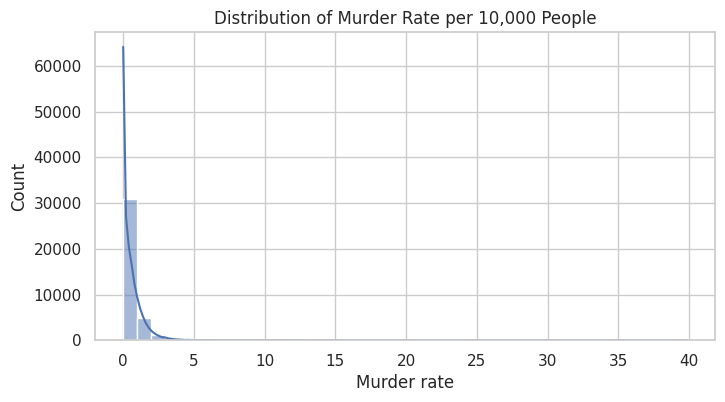

In [ ]:
if "murdrate" in analysis:
    plt.figure(figsize=(8, 4))
    sns.histplot(analysis["murdrate"], bins=40, kde=True)
    plt.title("Distribution of Murder Rate per 10,000 People")
    plt.xlabel("Murder rate")
    plt.show()

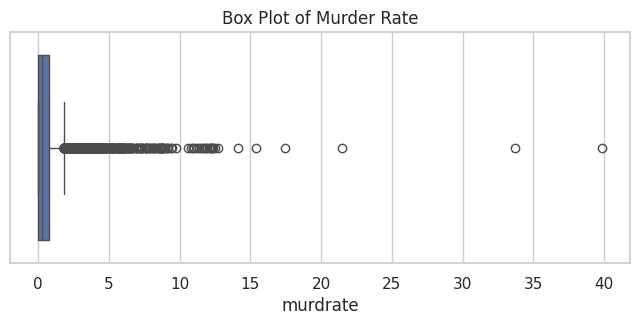

In [ ]:
if "murdrate" in analysis:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=analysis["murdrate"])
    plt.title("Box Plot of Murder Rate")
    plt.show()

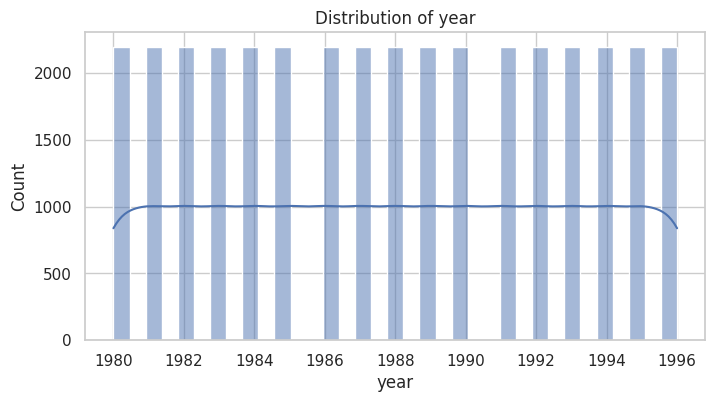

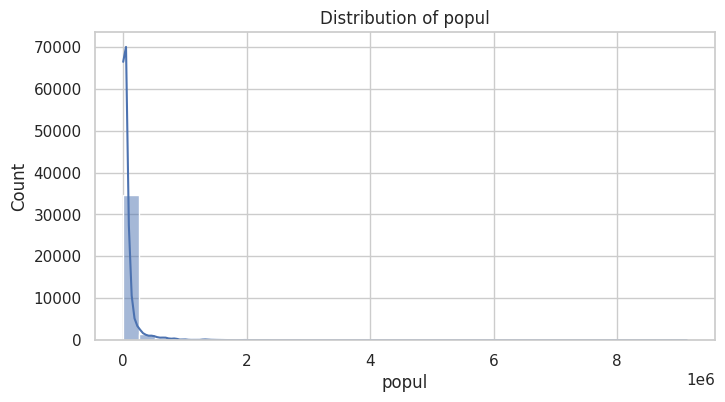

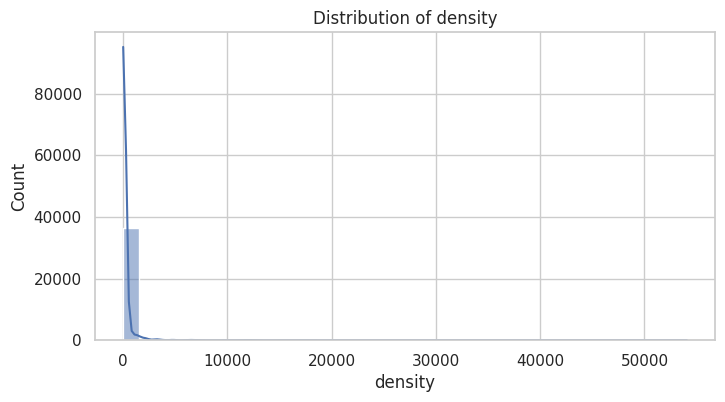

In [ ]:
for col in ["year", "popul", "density"]:
    if col in analysis:
        plt.figure(figsize=(8, 4))
        sns.histplot(analysis[col], bins=35, kde=True)
        plt.title(f"Distribution of {col}")
        plt.show()

### 5.2 Bivariate analysis
Bivariate analysis examines relationships between two variables. These plots explore murder rates against year, population density and demographic/economic indicators.

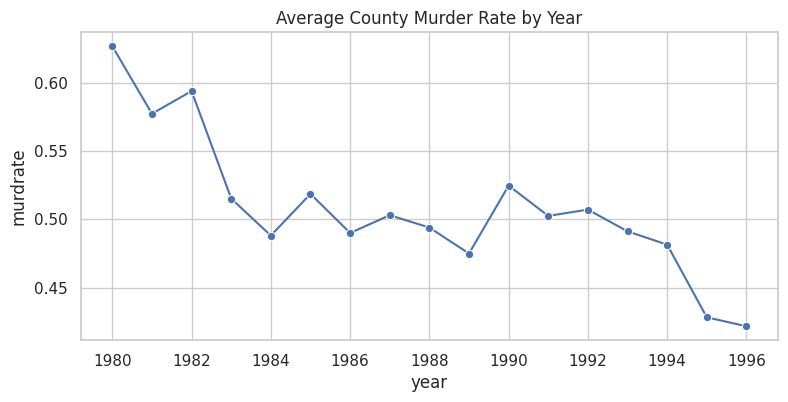

In [ ]:
if {"year", "murdrate"}.issubset(analysis.columns):
    yearly_rate = analysis.groupby("year", as_index=False)["murdrate"].mean()
    plt.figure(figsize=(9, 4))
    sns.lineplot(data=yearly_rate, x="year", y="murdrate", marker="o")
    plt.title("Average County Murder Rate by Year")
    plt.show()

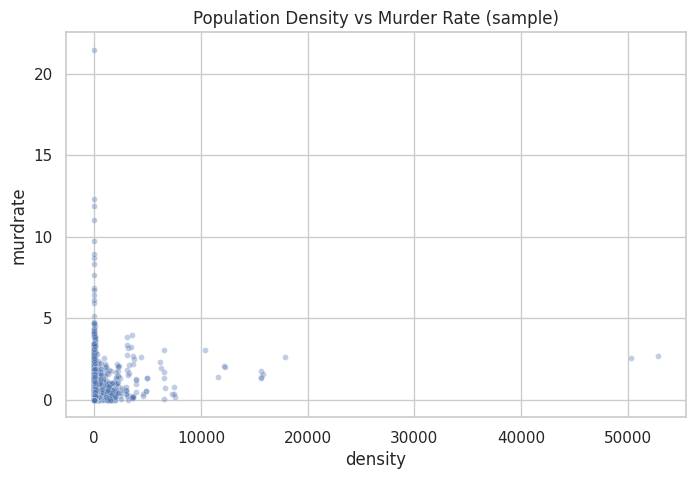

In [ ]:
if {"density", "murdrate"}.issubset(analysis.columns):
    sample = analysis.sample(min(5000, len(analysis)), random_state=RANDOM_STATE)
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=sample, x="density", y="murdrate", alpha=.35, s=18)
    plt.title("Population Density vs Murder Rate (sample)")
    plt.show()

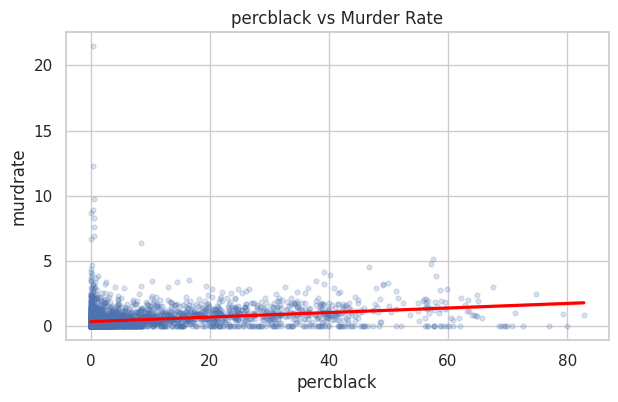

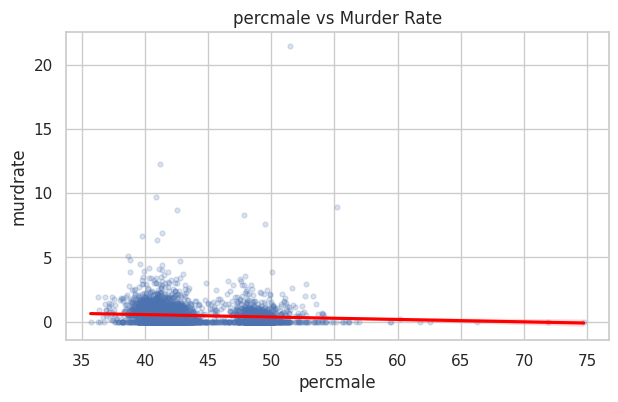

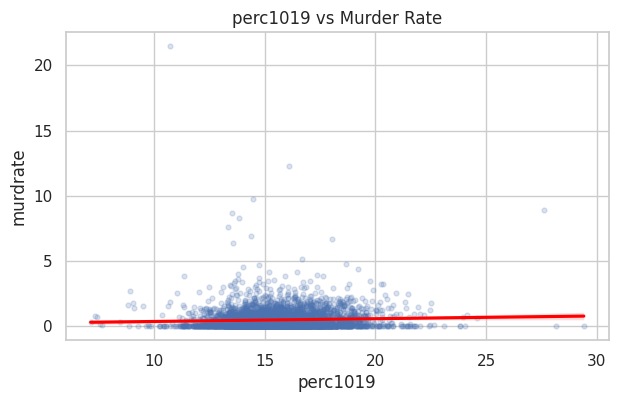

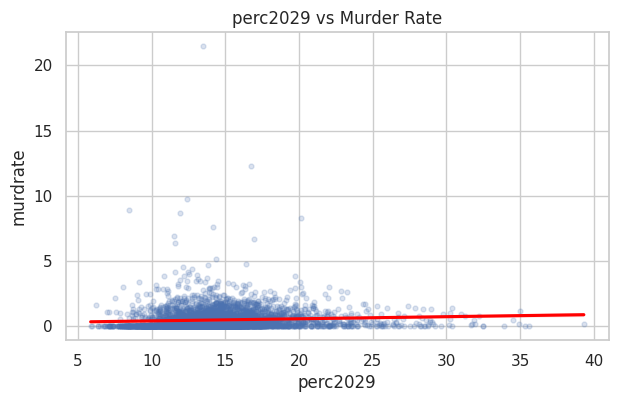

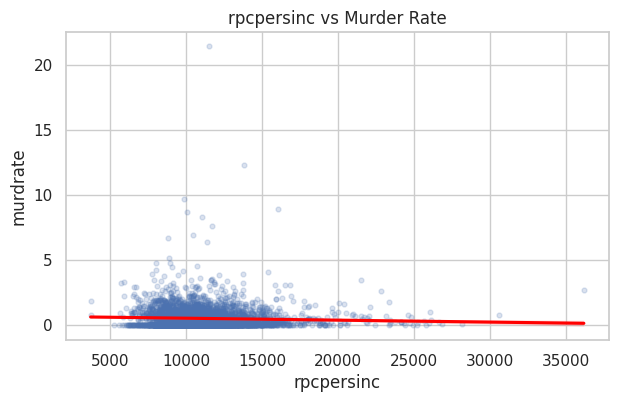

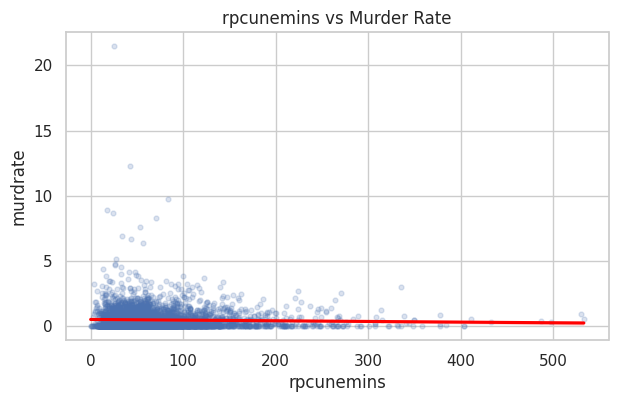

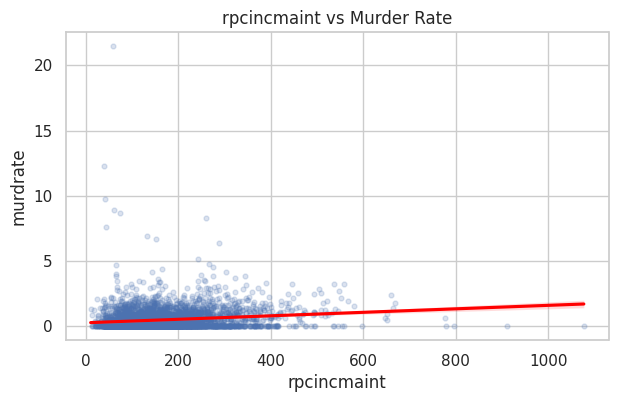

In [ ]:
for predictor in ["percblack", "percmale", "perc1019", "perc2029",
                  "rpcpersinc", "rpcunemins", "rpcincmaint"]:
    if predictor in analysis and "murdrate" in analysis:
        plt.figure(figsize=(7, 4))
        sns.regplot(data=analysis.sample(min(4000, len(analysis)), random_state=RANDOM_STATE),
                    x=predictor, y="murdrate", scatter_kws={"alpha": .2, "s": 12},
                    line_kws={"color": "red"})
        plt.title(f"{predictor} vs Murder Rate")
        plt.show()

### 5.3 Multivariate analysis
Multivariate analysis examines several variables together. The correlation heatmap shows pairwise linear associations among selected numeric columns; it does not establish causation.

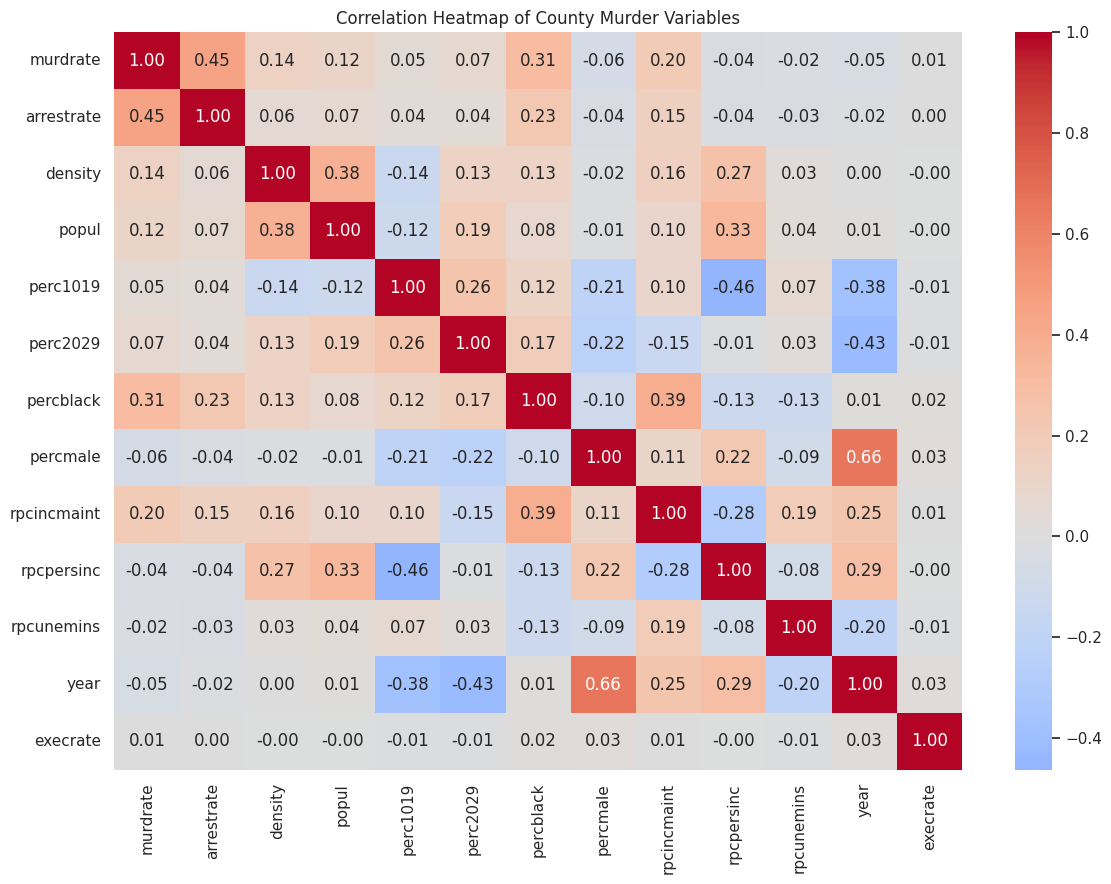

In [ ]:
corr_cols = [c for c in ["murdrate", "arrestrate", "density", "popul", "perc1019",
                         "perc2029", "percblack", "percmale", "rpcincmaint",
                         "rpcpersinc", "rpcunemins", "year", "execrate"] if c in analysis]
plt.figure(figsize=(12, 9))
sns.heatmap(analysis[corr_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap of County Murder Variables")
plt.tight_layout()
plt.show()

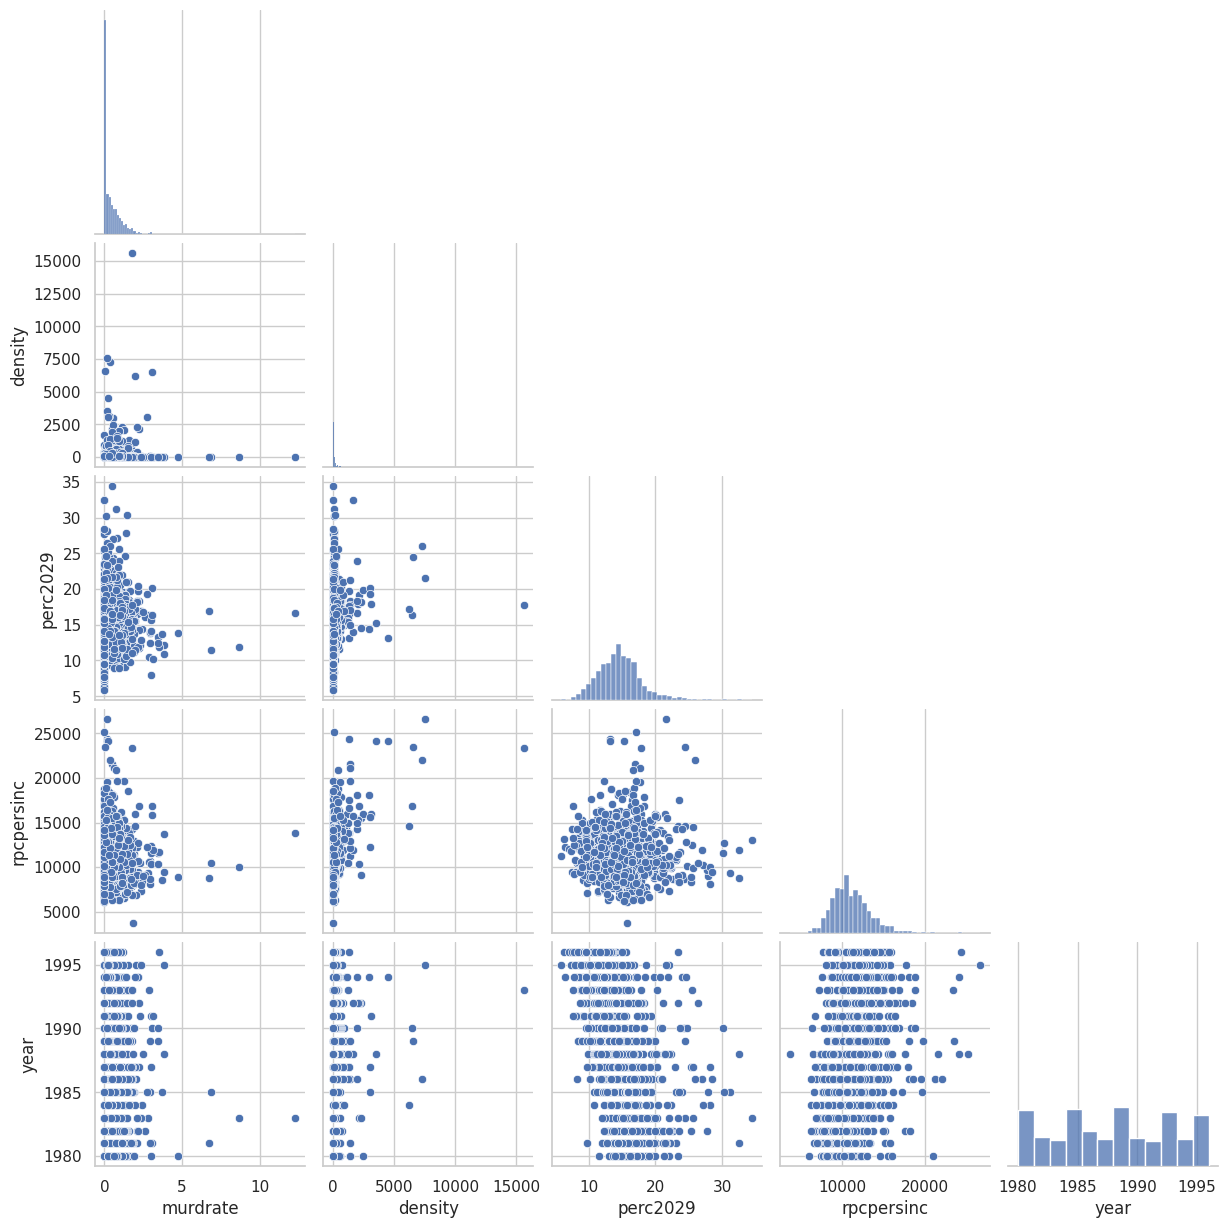

In [ ]:
pair_cols = [c for c in ["murdrate", "density", "perc2029", "rpcpersinc", "year"] if c in analysis]
if len(pair_cols) >= 2:
    sns.pairplot(analysis[pair_cols].sample(min(1200, len(analysis)), random_state=RANDOM_STATE),
                 corner=True, diag_kind="hist")
    plt.show()

## 6. Statistical Analysis – Module 3

### 6.1 One-dimensional statistical analysis
Measures such as mean, median, standard deviation, variance, skewness and kurtosis summarize each numeric variable's distribution.

In [ ]:
summary_cols = [c for c in ["murdrate", "arrestrate", "popul", "density", "perc1019",
                            "perc2029", "percblack", "percmale", "rpcpersinc", "year"]
                if c in analysis]
one_d = analysis[summary_cols].agg(["count", "mean", "median", "std", "var", "min", "max"]).T
one_d["skewness"] = analysis[summary_cols].skew()
one_d["kurtosis"] = analysis[summary_cols].kurtosis()
display(one_d.round(3))

,count,mean,median,std,var,min,max,skewness,kurtosis
murdrate,37349.0,0.508,0.241,0.851,7.240000e-01,0.000,39.841,8.503,229.196
arrestrate,37349.0,0.507,0.164,1.225,1.500000e+00,0.000,148.658,51.593,5802.513
popul,37349.0,89343.541,28792.000,271854.499,7.390487e+10,85.000,9127751.000,16.394,445.682
density,37349.0,252.241,44.240,1663.768,2.768126e+06,0.050,54058.770,20.857,540.340
perc1019,37349.0,15.583,15.420,1.973,3.894000e+00,7.080,30.485,0.486,2.005
perc2029,37349.0,14.585,14.270,3.696,1.366300e+01,5.617,40.520,1.424,4.779
percblack,37349.0,7.823,1.450,13.287,1.765460e+02,0.000,86.279,2.329,5.522
percmale,37349.0,43.351,41.810,3.718,1.382100e+01,35.150,78.040,1.130,0.922
rpcpersinc,37349.0,11272.262,10907.500,2680.641,7.185835e+06,3477.760,41094.220,1.606,6.201
year,37349.0,1988.000,1988.000,4.899,2.400100e+01,1980.000,1996.000,0.000,-1.208


In [ ]:
# Shapiro-Wilk is highly sensitive with large samples, so use a reproducible
# sample of at most 5,000 observations per variable.
normality_rows = []
for col in summary_cols:
    values = analysis[col].dropna()
    sample_values = values.sample(min(5000, len(values)), random_state=RANDOM_STATE)
    if len(sample_values) >= 3:
        stat, p = stats.shapiro(sample_values)
        normality_rows.append([col, stat, p])
normality = pd.DataFrame(normality_rows, columns=["variable", "shapiro_statistic", "p_value"])
display(normality)

,variable,shapiro_statistic,p_value
0,murdrate,0.577319,1.470653e-76
1,arrestrate,0.490736,1.513269e-80
2,popul,0.222357,5.458259e-90
3,density,0.108592,3.778365e-93
4,perc1019,0.974356,4.584056e-29
5,perc2029,0.913973,1.035231e-46
6,percblack,0.633062,1.332734e-73
7,percmale,0.834906,5.084775e-58
8,rpcpersinc,0.897404,1.213676e-49
9,year,0.949704,2.384858e-38


### 6.2 Two-dimensional statistical analysis
Pearson correlation measures linear association; Spearman correlation measures monotonic association using ranks. The tests below are run only when the relevant variables exist.

In [ ]:
pairs_to_test = [("density", "murdrate"), ("perc2029", "murdrate"),
                 ("rpcpersinc", "murdrate"), ("year", "murdrate")]
corr_results = []
for x, y in pairs_to_test:
    if {x, y}.issubset(analysis.columns):
        pearson_r, pearson_p = stats.pearsonr(analysis[x], analysis[y])
        spearman_r, spearman_p = stats.spearmanr(analysis[x], analysis[y])
        corr_results.append([x, y, pearson_r, pearson_p, spearman_r, spearman_p])
corr_table = pd.DataFrame(corr_results, columns=[
    "variable_1", "variable_2", "pearson_r", "pearson_p",
    "spearman_rho", "spearman_p"
])
display(corr_table.round(5))

,variable_1,variable_2,pearson_r,pearson_p,spearman_rho,spearman_p
0,density,murdrate,0.13759,0.0,0.27656,0.0
1,perc2029,murdrate,0.07448,0.0,0.23447,0.0
2,rpcpersinc,murdrate,-0.03501,0.0,-0.02379,0.0
3,year,murdrate,-0.04811,0.0,-0.06584,0.0


In [ ]:
# Compare murder rates across years using a one-way ANOVA on a limited number
# of year groups. This is descriptive association, not causal evidence.
if {"year", "murdrate"}.issubset(analysis.columns):
    year_groups = [g["murdrate"].values for _, g in analysis.groupby("year") if len(g) > 1]
    if len(year_groups) >= 2:
        f_stat, p_value = stats.f_oneway(*year_groups)
        print(f"One-way ANOVA across years: F={f_stat:.4f}, p={p_value:.6g}")

One-way ANOVA across years: F=8.2920, p=2.13341e-20


## 7. Clustering – Module 4
Clustering is unsupervised learning: it groups observations by similarity without using a known class label. For computational efficiency, the algorithms use a reproducible sample of up to 5,000 county-year records.

In [ ]:
cluster_candidates = [c for c in ["density", "lpopul", "perc1019", "perc2029",
                                  "percblack", "percmale", "rpcincmaint",
                                  "rpcpersinc", "rpcunemins", "year", "execrate"]
                      if c in analysis.columns]
cluster_data = analysis[cluster_candidates].sample(min(5000, len(analysis)),
                                                   random_state=RANDOM_STATE).copy()
cluster_data = cluster_data.replace([np.inf, -np.inf], np.nan)
cluster_imputer = SimpleImputer(strategy="median")
cluster_scaled = StandardScaler().fit_transform(cluster_imputer.fit_transform(cluster_data))
print("Features used:", cluster_candidates)
print("Clustering sample shape:", cluster_scaled.shape)

Features used: ['density', 'lpopul', 'perc1019', 'perc2029', 'percblack', 'percmale', 'rpcincmaint', 'rpcpersinc', 'rpcunemins', 'year', 'execrate']
Clustering sample shape: (5000, 11)


### 7.1 K-Means clustering

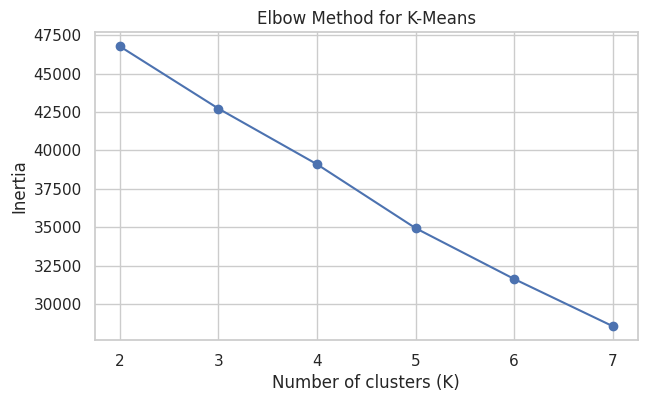

In [ ]:
inertias = []
k_values = range(2, 8)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(cluster_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(cluster_scaled)
cluster_data["kmeans_cluster"] = kmeans_labels
display(cluster_data.groupby("kmeans_cluster")[cluster_candidates].mean().round(2))

,density,lpopul,perc1019,perc2029,percblack,percmale,rpcincmaint,rpcpersinc,rpcunemins,year,execrate
kmeans_cluster,,,,,,,,,,,
0,273.71,10.16,14.52,12.02,4.43,48.09,182.55,12641.02,60.93,1993.60,0.00
1,438.74,10.47,16.74,15.84,37.11,41.48,274.28,9475.46,59.29,1987.42,0.01
2,155.50,10.39,15.88,15.66,3.66,41.55,134.77,10973.90,77.85,1985.57,0.00


### 7.2 Hierarchical clustering

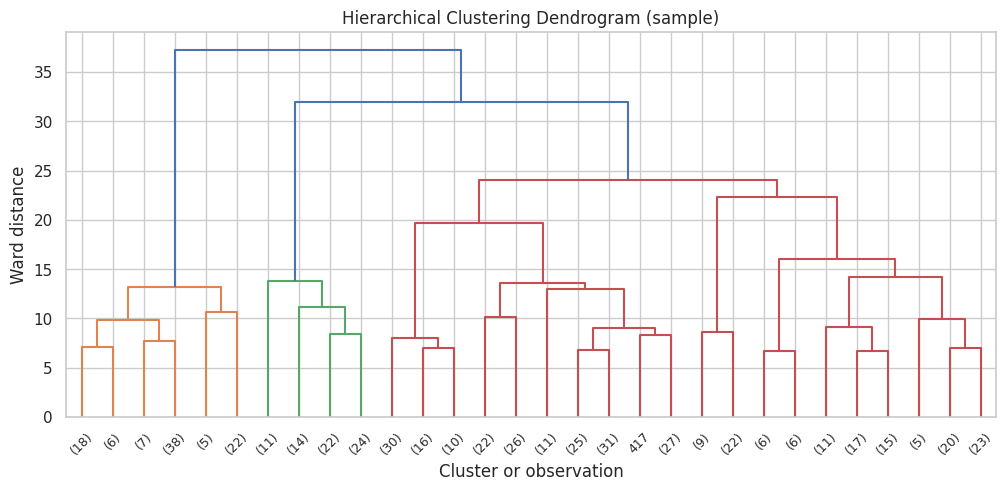

In [ ]:
# Ward linkage on a smaller subset keeps the dendrogram readable and efficient.
hier_n = min(500, len(cluster_scaled))
hier_sample = cluster_scaled[:hier_n]
Z = linkage(hier_sample, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45, leaf_font_size=9)
plt.title("Hierarchical Clustering Dendrogram (sample)")
plt.xlabel("Cluster or observation")
plt.ylabel("Ward distance")
plt.show()

In [ ]:
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")
hier_labels = hierarchical.fit_predict(hier_sample)
print("Hierarchical cluster counts:")
display(pd.Series(hier_labels).value_counts().sort_index().to_frame("observations"))

Hierarchical cluster counts:


,observations
0,333
1,96
2,71


## 8. Principal Component Analysis (PCA) – Module 6
PCA transforms correlated numeric variables into a smaller set of uncorrelated principal components. Identifiers and direct murder/arrest outcome fields are excluded.

In [ ]:
pca_features = [c for c in ["density", "lpopul", "perc1019", "perc2029",
                             "percblack", "percmale", "rpcincmaint",
                             "rpcpersinc", "rpcunemins", "year", "execrate"]
                if c in analysis.columns]
pca_frame = analysis[pca_features].replace([np.inf, -np.inf], np.nan)
pca_imputer = SimpleImputer(strategy="median")
pca_scaler = StandardScaler()
X_pca_scaled = pca_scaler.fit_transform(pca_imputer.fit_transform(pca_frame))
print("Original feature count:", len(pca_features))

Original feature count: 11


In [ ]:
pca_full = PCA()
pca_scores = pca_full.fit_transform(X_pca_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

variance_table = pd.DataFrame({
    "component": [f"PC{i+1}" for i in range(len(explained))],
    "explained_variance_ratio": explained,
    "cumulative_variance": cumulative
})
display(variance_table.round(4))

n_80 = int(np.argmax(cumulative >= 0.80) + 1)
print(f"Components needed to retain at least 80% variance: {n_80}")

,component,explained_variance_ratio,cumulative_variance
0,PC1,0.2164,0.2164
1,PC2,0.1681,0.3846
2,PC3,0.1468,0.5314
3,PC4,0.1026,0.6340
4,PC5,0.0905,0.7245
5,PC6,0.0805,0.8050
6,PC7,0.0644,0.8694
7,PC8,0.0450,0.9143
8,PC9,0.0407,0.9551
9,PC10,0.0257,0.9808


Components needed to retain at least 80% variance: 6


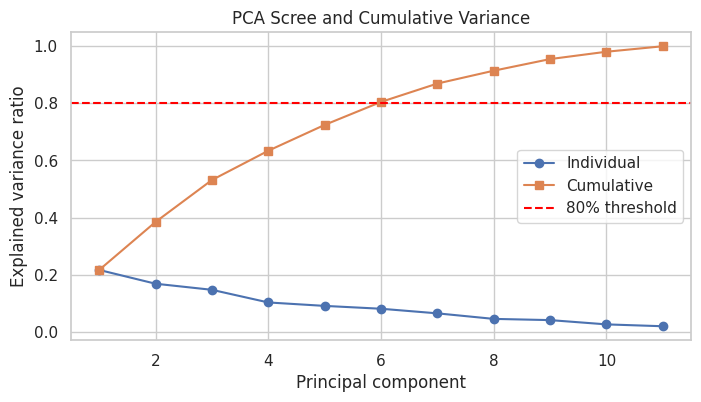

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(explained)+1), explained, marker="o", label="Individual")
plt.plot(range(1, len(explained)+1), cumulative, marker="s", label="Cumulative")
plt.axhline(0.80, linestyle="--", color="red", label="80% threshold")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA Scree and Cumulative Variance")
plt.legend()
plt.show()

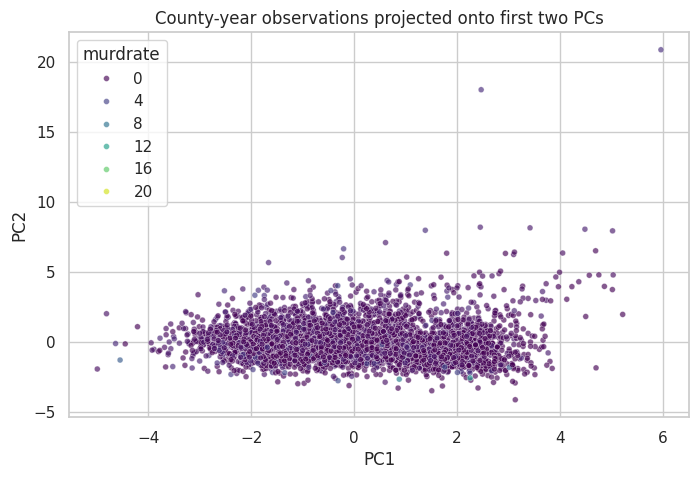

In [ ]:
pca_2 = PCA(n_components=2)
pca_2d = pca_2.fit_transform(X_pca_scaled)
pca_plot = pd.DataFrame(pca_2d, columns=["PC1", "PC2"])
pca_plot["murdrate"] = analysis["murdrate"].values if "murdrate" in analysis else np.nan
plt.figure(figsize=(8, 5))
sns.scatterplot(data=pca_plot.sample(min(5000, len(pca_plot)), random_state=RANDOM_STATE),
                x="PC1", y="PC2", hue="murdrate", palette="viridis", s=18, alpha=.65)
plt.title("County-year observations projected onto first two PCs")
plt.show()

,PC1,PC2,PC3,PC4,PC5
density,0.058,0.441,0.209,0.106,-0.006
lpopul,-0.021,0.601,0.106,0.062,0.018
perc1019,-0.430,-0.180,0.144,-0.093,-0.003
perc2029,-0.351,0.410,-0.038,-0.204,0.011
percblack,-0.124,0.129,0.548,-0.402,-0.066
percmale,0.465,-0.099,0.131,-0.005,0.008
rpcincmaint,0.021,-0.076,0.697,0.212,-0.012
rpcpersinc,0.360,0.452,-0.238,-0.007,0.000
rpcunemins,-0.148,0.056,0.083,0.839,0.138
year,0.552,-0.067,0.232,-0.067,-0.029


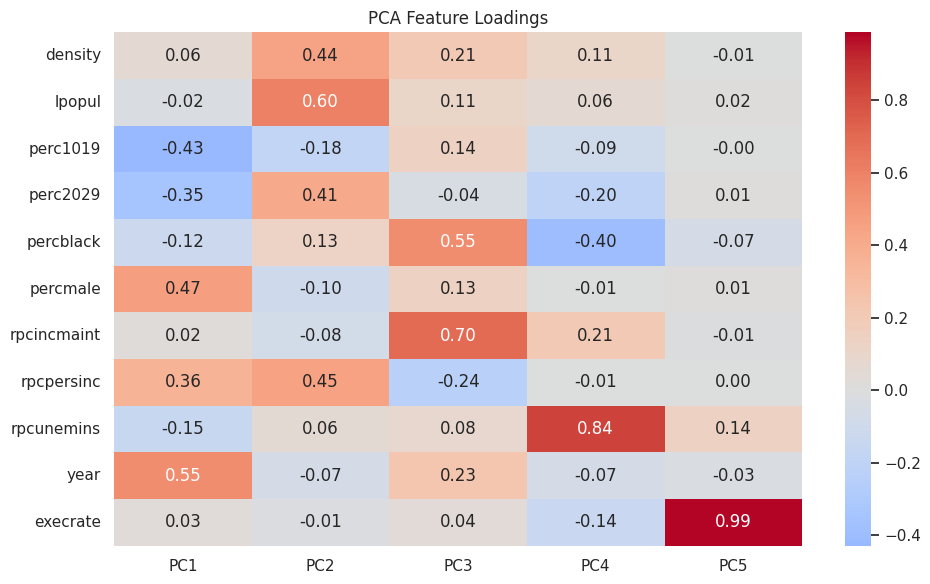

In [ ]:
loadings = pd.DataFrame(pca_full.components_.T,
                        index=pca_features,
                        columns=[f"PC{i+1}" for i in range(len(pca_features))])
display(loadings.iloc[:, :min(5, loadings.shape[1])].round(3))
plt.figure(figsize=(10, 6))
sns.heatmap(loadings.iloc[:, :min(5, loadings.shape[1])], cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

## 9. Classification – Module 7
The original dataset does not contain a categorical target for this task. We derive `high_murdrate` from whether `murdrate` is above its median. This is a supervised classification exercise using a transparent derived target. The predictors exclude `murdrate`, `murders`, `arrests`, and `arrestrate` to prevent direct target leakage.

In [ ]:
if "murdrate" not in analysis.columns:
    raise ValueError("The dataset must contain the murdrate column for this classification task.")

model_data = analysis.copy()
threshold = model_data["murdrate"].median()
model_data["high_murdrate"] = (model_data["murdrate"] > threshold).astype(int)
print("Median murder-rate threshold:", threshold)
print("Class distribution:")
display(model_data["high_murdrate"].value_counts().rename(index={0:"At or below median", 1:"Above median"}).to_frame("count"))

Median murder-rate threshold: 0.2410439
Class distribution:


,count
high_murdrate,
At or below median,18675
Above median,18674


In [ ]:
excluded = set(identifier_cols + outcome_cols + ["high_murdrate"])
candidate_features = [c for c in model_data.select_dtypes(include=np.number).columns
                      if c not in excluded]
# Keep meaningful demographic, economic, population and time predictors.
preferred = ["density", "popul", "lpopul", "perc1019", "perc2029", "percblack",
             "percmale", "rpcincmaint", "rpcpersinc", "rpcunemins", "year", "execs", "execrate"]
features = [c for c in preferred if c in candidate_features]
X = model_data[features].replace([np.inf, -np.inf], np.nan)
y = model_data["high_murdrate"]
print("Predictor features:", features)
print("X shape:", X.shape, "y shape:", y.shape)

Predictor features: ['density', 'popul', 'lpopul', 'perc1019', 'perc2029', 'percblack', 'percmale', 'rpcincmaint', 'rpcpersinc', 'rpcunemins', 'year', 'execs', 'execrate']
X shape: (37349, 13) y shape: (37349,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced"))
])
model.fit(X_train, y_train)
print("Training completed.")

Training completed.


In [ ]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)
model_pred = model.predict(X_test)

results = pd.DataFrame([
    ["Majority-class baseline",
     accuracy_score(y_test, baseline_pred),
     balanced_accuracy_score(y_test, baseline_pred),
     f1_score(y_test, baseline_pred, average="macro"),
     f1_score(y_test, baseline_pred, average="weighted")],
    ["Logistic Regression",
     accuracy_score(y_test, model_pred),
     balanced_accuracy_score(y_test, model_pred),
     f1_score(y_test, model_pred, average="macro"),
     f1_score(y_test, model_pred, average="weighted")]
], columns=["Model", "Accuracy", "Balanced accuracy", "Macro F1", "Weighted F1"])
display(results.round(4))
print(classification_report(y_test, model_pred, target_names=["At/below median", "Above median"]))

,Model,Accuracy,Balanced accuracy,Macro F1,Weighted F1
0,Majority-class baseline,0.5000,0.5000,0.3333,0.3333
1,Logistic Regression,0.6901,0.6901,0.6899,0.6899


                 precision    recall  f1-score   support

At/below median       0.68      0.71      0.70      3735
   Above median       0.70      0.67      0.68      3735

       accuracy                           0.69      7470
      macro avg       0.69      0.69      0.69      7470
   weighted avg       0.69      0.69      0.69      7470



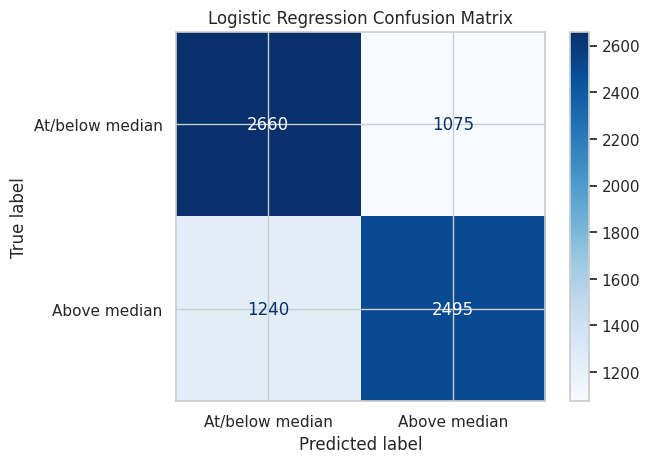

In [ ]:
cm = confusion_matrix(y_test, model_pred)
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=["At/below median", "Above median"]).plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [ ]:
cv_scores = cross_val_score(model, X, y, cv=5, scoring="f1_macro", n_jobs=-1)
print(f"5-fold cross-validation Macro F1: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

5-fold cross-validation Macro F1: 0.6869 ± 0.0282


## 10. Conclusion
This project applies the EDA workflow to a county-year murder dataset. It includes data inspection and cleaning, visual and statistical exploration, K-Means and hierarchical clustering, PCA for dimensionality reduction, and Logistic Regression for a derived high-murder-rate classification task. Interpretations should be treated as descriptive associations rather than causal conclusions. The classification label is created from the median murder rate solely for the course exercise; results do not imply that the model explains or causes crime.

## References
- Dataset: [countymurders.csv](https://raw.githubusercontent.com/salemprakash/EDA/main/Data/countymurders.csv)
- Dataset description: Wooldridge `countymurders` documentation. The documented source notes 37,349 observations, 20 variables, and data compiled from US Census Bureau, FBI Uniform Crime Reports, and Death Penalty Information Center sources.